# 数据增强对照实验

对比“无增强”与三种单独增强：
1. 随机水平翻转
2. 随机裁剪
3. 颜色扰动
最后再对比“全部叠加”。

In [1]:
import os
import random
import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from torchvision import datasets, transforms as T


#中文
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'PingFang SC']
plt.rcParams['axes.unicode_minus'] = False

import yaml
with open("config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.load(f, Loader=yaml.FullLoader)
root = cfg["dataset_root"]
train_root = os.path.join(root, "train")
raw_dataset = datasets.ImageFolder(train_root, transform=None)

# 用random随机选一张原图
random.seed(51)
idx = random.randint(0, len(raw_dataset) - 1)
img_path, img_label = raw_dataset.samples[idx]
raw_img = Image.open(img_path).convert("RGB")
idx_to_class = {v: k for k, v in raw_dataset.class_to_idx.items()}
print(f"原图: {img_path}, 类别: {idx_to_class[img_label]}")

原图: ./cats_and_dogs\train\cat\cat.593.jpg, 类别: cat


In [2]:
def tensor_to_image(tensor, denorm=True):
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])

    if tensor.dim() == 4:
        tensor = tensor[0]

    tensor = tensor.detach().cpu()
    img = tensor.permute(1, 2, 0).numpy()

    if denorm:
        img = img * std + mean

    return np.clip(img, 0, 1).astype(np.float32)

In [3]:
_mean = [0.485, 0.456, 0.406]
_std  = [0.229, 0.224, 0.225]

base_tf = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(_mean, _std),
])

def draw_compare_vs_base(raw_img, aug_tf, title_aug, seed=0):
    """显示三张图：原图 / 无增强 / 增强"""
    torch.manual_seed(seed)
    aug_tensor = aug_tf(raw_img)

    torch.manual_seed(seed)
    base_tensor = base_tf(raw_img)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(raw_img)
    axes[0].set_title("原图", fontsize=11)
    axes[0].axis("off")

    axes[1].imshow(tensor_to_image(base_tensor, denorm=True))
    axes[1].set_title("无增强", fontsize=11)
    axes[1].axis("off")

    axes[2].imshow(tensor_to_image(aug_tensor, denorm=True))
    axes[2].set_title(title_aug, fontsize=11)
    axes[2].axis("off")

    plt.suptitle(f"原图 / 无增强 / {title_aug}", fontsize=13)
    plt.tight_layout()
    plt.show()

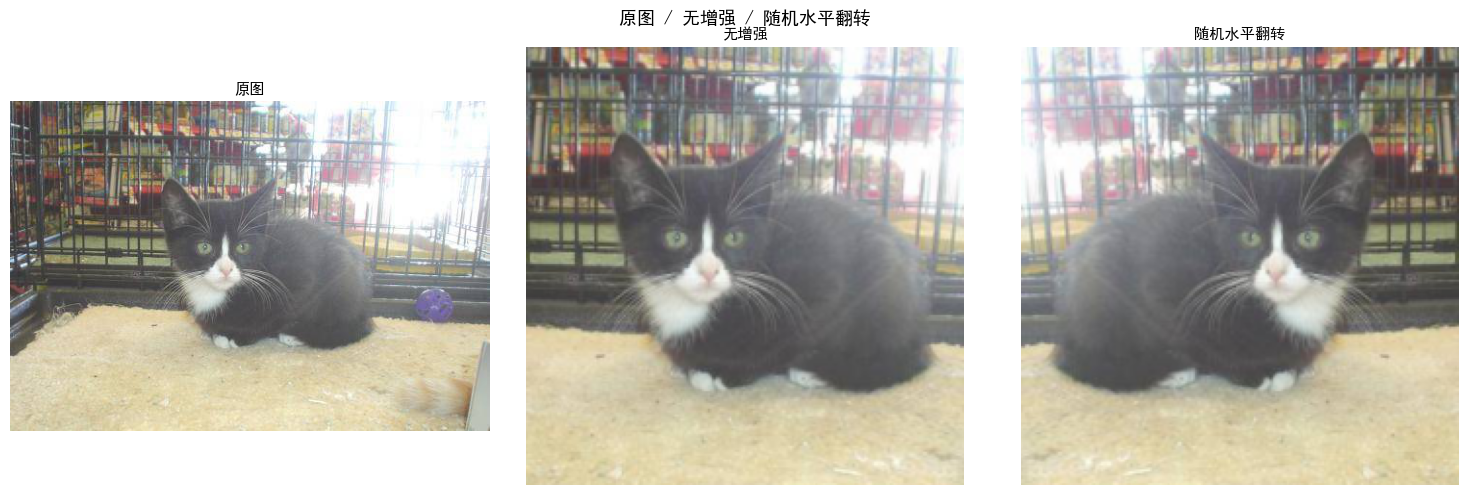

In [4]:
flip_tf = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.RandomHorizontalFlip(p=1.0),
    T.ToTensor(),
    T.Normalize(_mean, _std),
])

draw_compare_vs_base(raw_img, flip_tf, title_aug="随机水平翻转", seed=0)

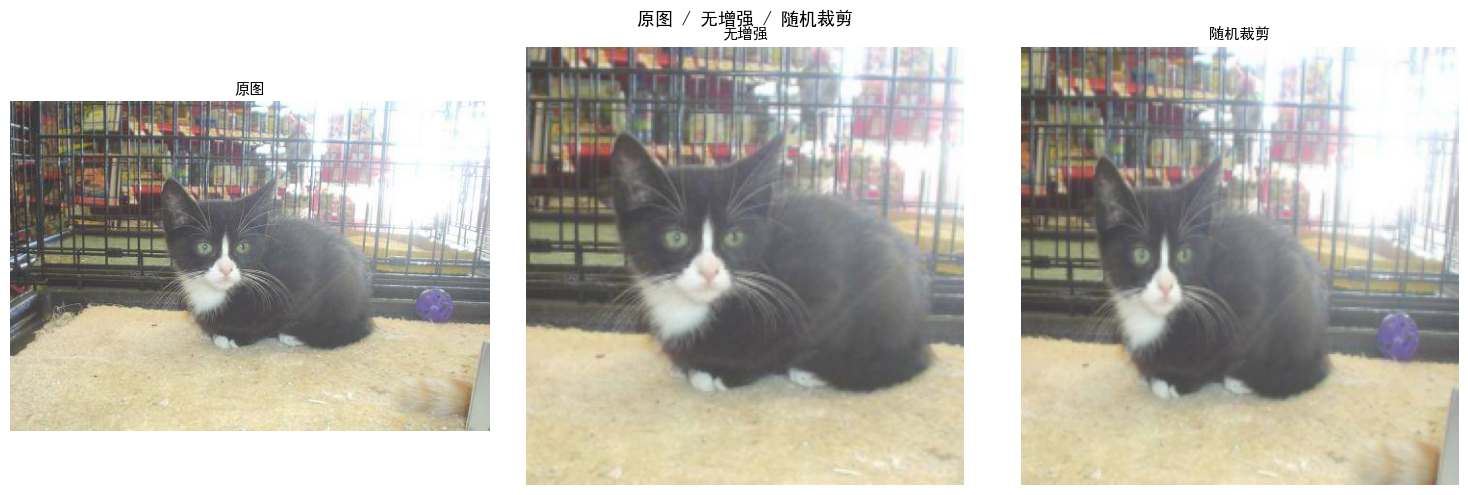

In [5]:
crop_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.5, 0.8)),
    T.ToTensor(),
    T.Normalize(_mean, _std),
])

draw_compare_vs_base(raw_img, crop_tf, title_aug="随机裁剪", seed=42)

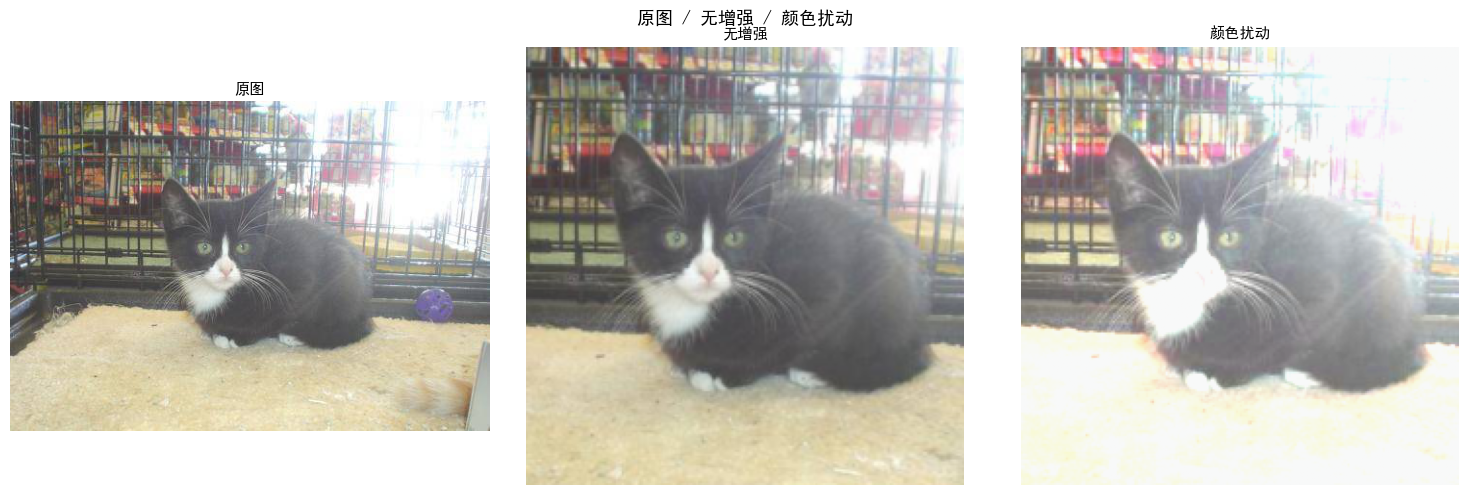

In [6]:
color_tf = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.5, hue=0.1),
    T.ToTensor(),
    T.Normalize(_mean, _std),
])

draw_compare_vs_base(raw_img, color_tf, title_aug="颜色扰动", seed=42)

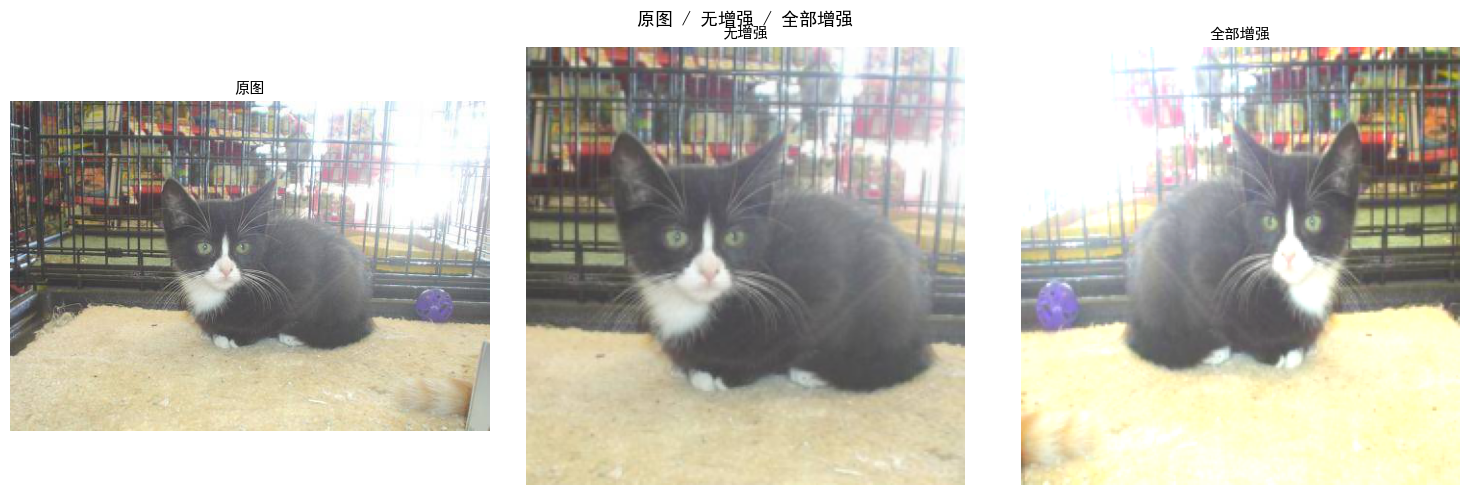

In [7]:
aug_all_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    T.ToTensor(),
    T.Normalize(_mean, _std),
])

draw_compare_vs_base(raw_img, aug_all_tf, title_aug="全部增强", seed=42)